# Phase 5: YOLO Segmentation (Comparison)

Train a YOLO segmentation model (Ultralytics **YOLO11s-seg**) on the **same train / val / test split** as the U-Net, then compare the two.

YOLO finds each lesion as a separate object with a **box**, a **mask** and a **confidence score**. We use one class, `lesion`, so YOLO answers *is there a tumour, how many, where and how big*. Benign vs malignant comes from the classifier or the multi-task U-Net.

**Input:** `data/manifest.csv` (created by `00_clean_data.ipynb`)

**Output** (saved to `outputs/yolo/`):

| File | What it contains |
| ---- | ---------------- |
| `dataset/` | The data converted to YOLO format (images, polygon labels, `data.yaml`) |
| `model.pt` | Trained YOLO weights (best epoch) |
| `config.json` | Image size, confidence threshold and training settings |
| `history.csv` | Losses and mAP for every epoch |
| `metrics.json` | Test results: mAP, Dice, IoU, false and missed lesions |
| `test_predictions.csv` | Detections, Dice and lesion area for every test image |
| `masks/` | Predicted mask for every test image, at the original size (same format as U-Net, for `04_measure`) |
| `train/`, `test/` | YOLO's own plots (results, PR curves, confusion matrix, sample batches) |
| `training_curves.png`, `prediction_examples.png`, `worst_predictions.png` | Our result plots |
| `../model_comparison.csv` | U-Net vs multi-task U-Net vs YOLO, side by side |

**Before the first run:** install Ultralytics with `.env/bin/pip install ultralytics`. The pretrained weights (`yolo11s-seg.pt`, about 20 MB) download automatically the first time.

> **Licence:** Ultralytics YOLO is AGPL-3.0. That's fine for learning and research; commercial use needs an Ultralytics licence.

## 1. Imports

In [1]:
import json
import shutil
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
from PIL import Image
from skimage.measure import label, regionprops, find_contours, approximate_polygon
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/Users/prajwalnerkar/Library/Application Support/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## 2. Settings

In [2]:
DATA_DIR = Path('data')
YOLO_DIR = Path('outputs/yolo')            # everything for this model is saved here
DATASET_DIR = YOLO_DIR / 'dataset'         # data converted to YOLO format
MASK_DIR = YOLO_DIR / 'masks'              # predicted test masks
YOLO_DIR.mkdir(parents=True, exist_ok=True)

PRETRAINED = 'yolo11s-seg.pt'   # small YOLO11 segmentation model, pretrained on COCO
IMAGE_SIZE = 640                # YOLO's standard input size (images are padded to a square)
BATCH_SIZE = 8
EPOCHS = 100                    # maximum; training can stop earlier
PATIENCE = 20                   # stop if validation hasn't improved for this many epochs
CONF_THRESHOLD = 0.25           # detections below this confidence are ignored
MIN_LESION_PIXELS = 50          # same as the other notebooks: smaller regions are noise
RANDOM_STATE = 42

DEVICE = 'mps' if torch.backends.mps.is_available() else 'cpu'   # Apple GPU if available
print('Using device:', DEVICE)

manifest = pd.read_csv(DATA_DIR / 'manifest.csv')
test_df = manifest[manifest['split'] == 'test'].reset_index(drop=True)
print(manifest['split'].value_counts().to_string())

Using device: mps
split
train    485
test     104
val      104


## 3. Convert the data to YOLO format

YOLO needs a specific folder layout, with one text file of labels per image:

```
dataset/
├── images/train/benign_12.png     ├── labels/train/benign_12.txt
├── images/val/...                 ├── labels/val/...
├── images/test/...                ├── labels/test/...
└── data.yaml                      (where the folders are + class names)
```

Each line of a label file is one lesion: `0 x1 y1 x2 y2 ...`. `0` is the class (`lesion`) and the numbers are the corners of its **outline polygon**, divided by the image width / height so they go from 0 to 1.

To get the polygon, we trace the outline of each separate lesion in the mask and simplify it to fewer points. **Normal** images get an **empty** label file: this teaches YOLO that some scans contain nothing.

Files are renamed without spaces or brackets (`benign (12).png` becomes `benign_12.png`), and the same split as the manifest is used.

In [3]:
def load_true_mask(mask_paths):
    """Merge an image's ground-truth masks into one True/False array."""
    masks = [np.array(Image.open(DATA_DIR / p).convert('L')) > 127 for p in mask_paths.split(';')]
    return np.any(masks, axis=0)


def mask_to_polygons(mask):
    """Outline of each separate lesion in a True/False mask, as a list of polygons [(x, y), ...] in pixels."""
    polygons = []
    labelled = label(mask, connectivity=2)                       # number each separate region
    for region in regionprops(labelled):
        if region.area < MIN_LESION_PIXELS:
            continue                                             # skip tiny specks
        lesion = np.pad(labelled == region.label, 1)             # 1-pixel border so outlines at the edge close
        outline = max(find_contours(lesion.astype(float), 0.5), key=len)    # outer outline = longest contour
        outline = approximate_polygon(outline, tolerance=1.0) - 1          # fewer points, undo the border
        polygons.append([(x, y) for y, x in outline])                      # (row, col) -> (x, y)
    return polygons


def polygon_to_label(polygon, width, height):
    """One YOLO label line: class 0, then x y pairs scaled to 0..1."""
    coords = ' '.join(f'{np.clip(x / width, 0, 1):.5f} {np.clip(y / height, 0, 1):.5f}' for x, y in polygon)
    return f'0 {coords}'


def yolo_name(image_path):
    """'benign/benign (12).png' -> 'benign_12' (no spaces or brackets)."""
    return Path(image_path).stem.replace(' (', '_').replace(')', '')

In [4]:
for folder in ['images', 'labels']:
    for split in ['train', 'val', 'test']:
        (DATASET_DIR / folder / split).mkdir(parents=True, exist_ok=True)

n_polygons = 0
for row in manifest.itertuples():
    name = yolo_name(row.image_path)
    shutil.copy(DATA_DIR / row.image_path, DATASET_DIR / 'images' / row.split / f'{name}.png')

    mask = load_true_mask(row.mask_paths)
    height, width = mask.shape
    lines = [polygon_to_label(p, width, height) for p in mask_to_polygons(mask)]   # empty for normal images
    (DATASET_DIR / 'labels' / row.split / f'{name}.txt').write_text('\n'.join(lines))
    n_polygons += len(lines)

# Tell YOLO where the data is and what the classes are
data_yaml = DATASET_DIR / 'data.yaml'
data_yaml.write_text(
    f"path: '{DATASET_DIR.resolve()}'\n"
    'train: images/train\n'
    'val: images/val\n'
    'test: images/test\n'
    'names:\n'
    '  0: lesion\n'
)
print(f'Converted {len(manifest)} images with {n_polygons} lesion outlines')
print(data_yaml.read_text())

Converted 693 images with 595 lesion outlines
path: '/Users/prajwalnerkar/Prajwal/Projects/Breast Cancer Detection/ultrasonic_scans/outputs/yolo/dataset'
train: images/train
val: images/val
test: images/test
names:
  0: lesion



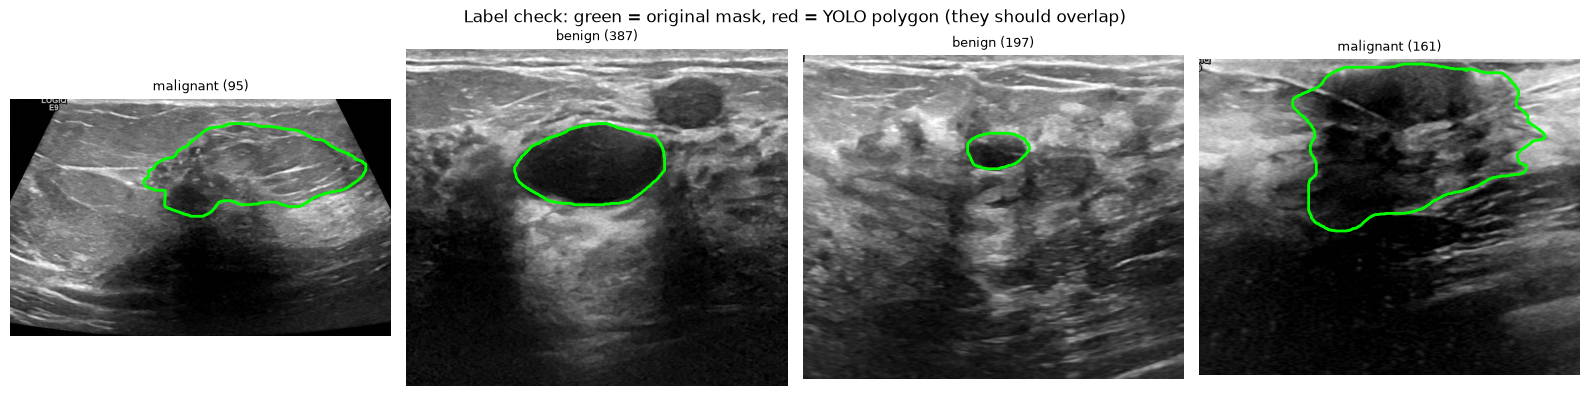

In [5]:
# Check the conversion: draw the YOLO polygons (red) over the original masks (green)
samples = manifest[manifest['label'] != 'normal'].sample(4, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, row in zip(axes, samples.itertuples()):
    image = Image.open(DATA_DIR / row.image_path).convert('L')
    width, height = image.size
    ax.imshow(image, cmap='gray')
    ax.contour(load_true_mask(row.mask_paths), levels=[0.5], colors='lime', linewidths=2)

    label_file = DATASET_DIR / 'labels' / row.split / f'{yolo_name(row.image_path)}.txt'
    for line in label_file.read_text().splitlines():
        values = np.array(line.split()[1:], dtype=float).reshape(-1, 2) * [width, height]   # back to pixels
        ax.add_patch(patches.Polygon(values, fill=False, edgecolor='red', linewidth=1.2))
    ax.set_title(Path(row.image_path).stem, fontsize=9)
    ax.axis('off')

plt.suptitle('Label check: green = original mask, red = YOLO polygon (they should overlap)')
plt.tight_layout()
plt.show()

## 4. Train

We fine-tune a YOLO11s-seg model pretrained on the COCO dataset. Ultralytics handles augmentation, validation after each epoch, early stopping and saving the best weights.

We change only the augmentations that matter for ultrasound:
- `flipud=0.0`: never flip up-down, because the skin is always at the top
- `fliplr=0.5`: left-right flips are fine
- `degrees=10`: small rotations, the same as the U-Net

In [6]:
model = YOLO(PRETRAINED)                     # downloads the pretrained weights the first time

model.train(
    data=str(data_yaml),
    epochs=EPOCHS,
    patience=PATIENCE,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    seed=RANDOM_STATE,
    project=str(YOLO_DIR.resolve()),         # save YOLO's run inside outputs/yolo/
    name='train',
    exist_ok=True,                           # overwrite the previous run
    flipud=0.0,                              # no up-down flips
    fliplr=0.5,                              # left-right flips half the time
    degrees=10,                              # small rotations
)

Ultralytics 8.4.209 🚀 Python-3.14.4 torch-2.15.0 MPS (Apple M5)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=outputs/yolo/dataset/data.yaml, degrees=10, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, over

/Users/prajwalnerkar/Prajwal/Projects/Breast Cancer Detection/.env/lib/python3.14/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/prajwalnerkar/Prajwal/Projects/Breast Cancer Detection/.env/lib/python3.14/site-packages/torch/autograd/graph.py:1113: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding determi

      1/100      5.38G      1.544      2.914      2.649      1.603          0          9        640: 100% ━━━━━━━━━━━━ 61/61 1.4it/s 44.6s0.8ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.5it/s 4.6s0.7ss
                   all        104         91       0.11      0.033     0.0144      0.007     0.0608      0.011    0.00838    0.00125

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
      2/100      5.32G      1.384       2.61      2.133      1.449          0         13        640: 0% ──────────── 0/61  0.7s

/Users/prajwalnerkar/Prajwal/Projects/Breast Cancer Detection/.env/lib/python3.14/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/prajwalnerkar/Prajwal/Projects/Breast Cancer Detection/.env/lib/python3.14/site-packages/torch/autograd/graph.py:1113: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding determi

      2/100      5.37G      1.702      2.798      2.154      1.739          0          6        640: 100% ━━━━━━━━━━━━ 61/61 1.7it/s 36.8s0.6ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.2it/s 3.2s0.6s
                   all        104         91      0.512      0.242      0.258       0.11      0.495      0.231      0.229     0.0867

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
      3/100      6.34G      1.456      2.621      1.528       1.49          0         15        640: 0% ──────────── 0/61  1.0s

/Users/prajwalnerkar/Prajwal/Projects/Breast Cancer Detection/.env/lib/python3.14/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/prajwalnerkar/Prajwal/Projects/Breast Cancer Detection/.env/lib/python3.14/site-packages/torch/autograd/graph.py:1113: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding determi

... (152 outputs left out)

     79/100       6.4G      1.038      1.873     0.9126      1.237          0          7        640: 100% ━━━━━━━━━━━━ 61/61 1.3it/s 47.1s0.7ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.0it/s 3.4s0.6s
                   all        104         91      0.847      0.802      0.869      0.568      0.847      0.802      0.863      0.565

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size


/Users/prajwalnerkar/Prajwal/Projects/Breast Cancer Detection/.env/lib/python3.14/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/prajwalnerkar/Prajwal/Projects/Breast Cancer Detection/.env/lib/python3.14/site-packages/torch/autograd/graph.py:1113: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding determi

     80/100      6.39G     0.9834      1.802     0.8617      1.202          0         13        640: 100% ━━━━━━━━━━━━ 61/61 1.3it/s 47.0s0.7ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.2it/s 3.3s0.6s
                   all        104         91      0.918      0.791       0.88      0.584      0.921      0.768      0.872      0.577
EarlyStopping: Training stopped early as no improvement observed in last 20 epochs. Best results observed at epoch 60, best model saved as best.pt.
To update EarlyStopping(patience=20) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.

80 epochs completed in 1.198 hours.
Optimizer stripped from /Users/prajwalnerkar/Prajwal/Projects/Breast Cancer Detection/ultrasonic_scans/outputs/yolo/train/weights/last.pt, 20.5MB
Optimizer stripped from /Users/prajwalnerkar/Prajwal/Projects/Breast Cancer Detection/ult

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x154f4a040>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    

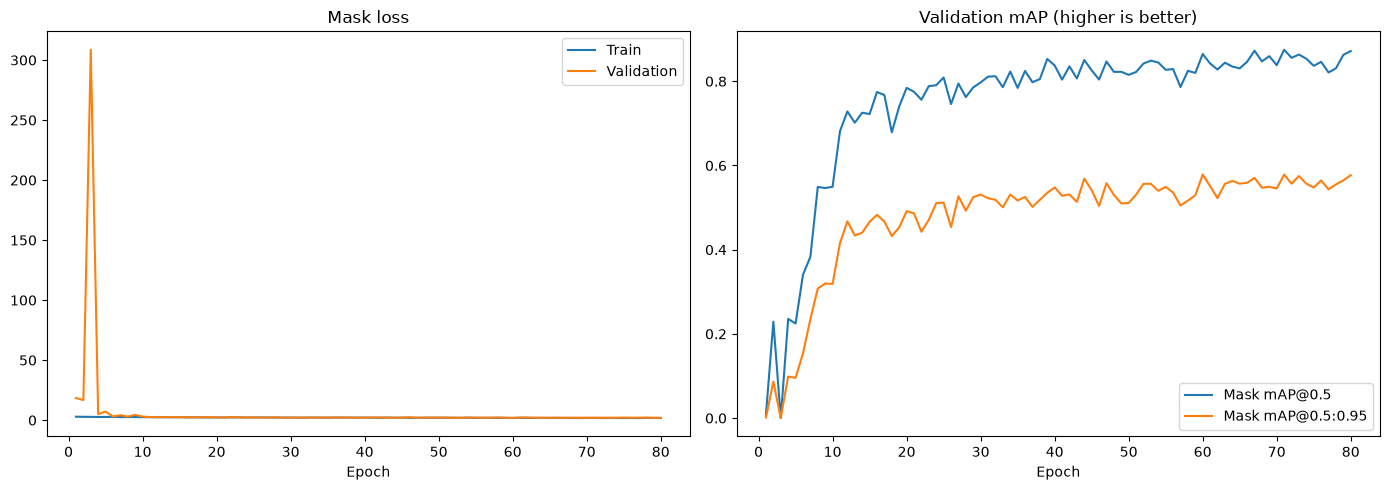

In [7]:
TRAIN_DIR = YOLO_DIR / 'train'
shutil.copy(TRAIN_DIR / 'weights' / 'best.pt', YOLO_DIR / 'model.pt')     # same file name as the other models

history = pd.read_csv(TRAIN_DIR / 'results.csv')
history.columns = history.columns.str.strip()                             # YOLO pads column names with spaces
history.to_csv(YOLO_DIR / 'history.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history['epoch'], history['train/seg_loss'], label='Train')
axes[0].plot(history['epoch'], history['val/seg_loss'], label='Validation')
axes[0].set_title('Mask loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history['epoch'], history['metrics/mAP50(M)'], label='Mask mAP@0.5')
axes[1].plot(history['epoch'], history['metrics/mAP50-95(M)'], label='Mask mAP@0.5:0.95')
axes[1].set_title('Validation mAP (higher is better)')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.tight_layout()
plt.savefig(YOLO_DIR / 'training_curves.png', dpi=120, bbox_inches='tight')
plt.show()

## 5. Evaluate on the test set

### YOLO's own metric: mAP

**mAP** (mean average precision) is the standard score for detection models. It measures how well the predicted lesions match the true ones across all confidence levels.
- **mAP@0.5:** a lesion counts as found if its overlap with the true one is at least 50%.
- **mAP@0.5:0.95:** the average over stricter overlaps (50% up to 95%). This is a harder, more precise score.

We report it for both the **masks** and the **boxes**.

In [8]:
best_model = YOLO(YOLO_DIR / 'model.pt')
test_scores = best_model.val(data=str(data_yaml), split='test', imgsz=IMAGE_SIZE, device=DEVICE,
                             project=str(YOLO_DIR.resolve()), name='test', exist_ok=True)

metrics = {
    'mask_map50': float(test_scores.seg.map50),
    'mask_map50_95': float(test_scores.seg.map),
    'box_map50': float(test_scores.box.map50),
    'box_map50_95': float(test_scores.box.map),
}
metrics

Ultralytics 8.4.209 🚀 Python-3.14.4 torch-2.15.0 MPS (Apple M5)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.1 ms, read: 1359.2±196.0 MB/s, size: 384.2 KB)
val: Scanning /Users/prajwalnerkar/Prajwal/Projects/Breast Cancer Detection/ultrasonic_scans/outputs/yolo/dataset/labels/test... 104 images, 17 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 104/104 2.1Kit/s 0.1s
val: New cache created: /Users/prajwalnerkar/Prajwal/Projects/Breast Cancer Detection/ultrasonic_scans/outputs/yolo/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.4it/s 2.9s0.5s
                   all        104         88      0.848      0.823       0.88      0.602      0.848      0.823      0.881      0.613
Speed: 0.2ms preprocess, 9.3ms inference, 0.0ms loss, 9.5ms postprocess per image
Results saved to /Users/

{'mask_map50': 0.8811024888649174,
 'mask_map50_95': 0.6132564378659405,
 'box_map50': 0.8798879138116094,
 'box_map50_95': 0.602052719169814}

### The same scores as the U-Net

To compare fairly, we turn YOLO's detections into one mask per image, **at the original image size**, exactly like the U-Net's saved masks. Then we compute the same Dice and IoU, and count false and missed lesions. The masks are saved to `masks/` so `04_measure` can measure them too.

In [9]:
def predict_mask(net, image, conf=CONF_THRESHOLD, image_size=IMAGE_SIZE, device=DEVICE):
    """Run YOLO on one PIL image. Returns (True/False mask at the original size, list of detections)."""
    width, height = image.size
    result = net.predict(image.convert('RGB'), imgsz=image_size, conf=conf, retina_masks=True,
                         device=device, verbose=False)[0]

    mask = np.zeros((height, width), dtype=bool)
    detections = []
    if result.masks is not None:                                     # None when nothing was found
        lesion_masks = result.masks.data.cpu().numpy()
        boxes = result.boxes.xyxy.cpu().numpy()
        scores = result.boxes.conf.cpu().numpy()
        for lesion, box, score in zip(lesion_masks, boxes, scores):
            lesion = lesion > 0.5
            if lesion.shape != (height, width):                      # safety: resize to the original size
                lesion = np.array(Image.fromarray(lesion.astype(np.uint8) * 255)
                                  .resize((width, height), Image.NEAREST)) > 127
            mask |= lesion                                           # merge all lesions into one mask
            detections.append({'confidence': round(float(score), 3),
                               'box': [round(float(v), 1) for v in box]})   # [left, top, right, bottom]
    return mask, detections


def dice_score(pred, truth):
    """Overlap of two True/False masks: 1 = identical, 0 = no overlap."""
    total = pred.sum() + truth.sum()
    return 1.0 if total == 0 else float(2 * (pred & truth).sum() / total)


def iou_score(pred, truth):
    """Intersection over union of two True/False masks: 1 = identical, 0 = no overlap."""
    union = (pred | truth).sum()
    return 1.0 if union == 0 else float((pred & truth).sum() / union)

In [10]:
rows, all_detections = [], {}
for row in test_df.itertuples():
    pred, detections = predict_mask(best_model, Image.open(DATA_DIR / row.image_path))
    truth = load_true_mask(row.mask_paths)
    all_detections[row.image_path] = detections

    mask_path = MASK_DIR / row.image_path                       # same layout as the U-Net masks
    mask_path.parent.mkdir(parents=True, exist_ok=True)
    Image.fromarray(pred.astype(np.uint8) * 255).save(mask_path)

    rows.append({
        'image_path': row.image_path,
        'label': row.label,
        'has_markers': row.has_markers,
        'pred_mask_path': str(mask_path.relative_to(YOLO_DIR)),
        'n_detections': len(detections),
        'max_confidence': max((d['confidence'] for d in detections), default=0.0),
        'tumour_detected': len(detections) > 0,
        'dice': dice_score(pred, truth),
        'iou': iou_score(pred, truth),
        'true_area_px': int(truth.sum()),
        'pred_area_px': int(pred.sum()),
    })

results = pd.DataFrame(rows)
results.to_csv(YOLO_DIR / 'test_predictions.csv', index=False)
print(f'Saved {len(results)} predicted masks to {MASK_DIR}')
results.head()

Saved 104 predicted masks to outputs/yolo/masks


,image_path,label,has_markers,pred_mask_path,n_detections,max_confidence,tumour_detected,dice,iou,true_area_px,pred_area_px
0,normal/normal (103).png,normal,False,masks/normal/normal (103).png,1,0.368,True,0.0,0.0,0,23088
1,normal/normal (108).png,normal,True,masks/normal/normal (108).png,1,0.297,True,0.0,0.0,0,16126
2,normal/normal (114).png,normal,True,masks/normal/normal (114).png,0,0.000,False,1.0,1.0,0,0
3,normal/normal (115).png,normal,False,masks/normal/normal (115).png,0,0.000,False,1.0,1.0,0,0
4,normal/normal (120).png,normal,False,masks/normal/normal (120).png,0,0.000,False,1.0,1.0,0,0


In [11]:
tumour = results['label'] != 'normal'

metrics.update({
    # Outline quality (tumour images only, like the U-Net)
    'dice_tumour_images': float(results.loc[tumour, 'dice'].mean()),
    'iou_tumour_images': float(results.loc[tumour, 'iou'].mean()),
    'dice_benign': float(results.loc[results['label'] == 'benign', 'dice'].mean()),
    'dice_malignant': float(results.loc[results['label'] == 'malignant', 'dice'].mean()),
    # False and missed lesions
    'normal_images_with_false_lesion': float((results.loc[~tumour, 'pred_area_px'] >= MIN_LESION_PIXELS).mean()),
    'tumour_images_with_no_lesion_found': float((results.loc[tumour, 'pred_area_px'] < MIN_LESION_PIXELS).mean()),
    # Tumour or not: any detection = tumour
    'tumour_sensitivity': float(results.loc[tumour, 'tumour_detected'].mean()),
    'tumour_specificity': float((~results.loc[~tumour, 'tumour_detected']).mean()),
    'test_images': int(len(results)),
})

# Shortcut check: outline quality on images with vs without markers
marker_check = results[tumour].groupby('has_markers')['dice'].agg(dice='mean', images='count')
metrics['dice_with_markers'] = float(marker_check['dice'].get(True, float('nan')))
metrics['dice_without_markers'] = float(marker_check['dice'].get(False, float('nan')))

(YOLO_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2))
for name, value in metrics.items():
    print(f'{name:36s} {value:.3f}' if isinstance(value, float) else f'{name:36s} {value}')

mask_map50                           0.881
mask_map50_95                        0.613
box_map50                            0.880
box_map50_95                         0.602
dice_tumour_images                   0.751
iou_tumour_images                    0.679
dice_benign                          0.777
dice_malignant                       0.701
normal_images_with_false_lesion      0.412
tumour_images_with_no_lesion_found   0.103
tumour_sensitivity                   0.897
tumour_specificity                   0.588
test_images                          104
dice_with_markers                    0.725
dice_without_markers                 0.798


## 6. See the predictions

**Green** = true outline, **red** = YOLO's mask, **yellow box** = YOLO's detection with its confidence.

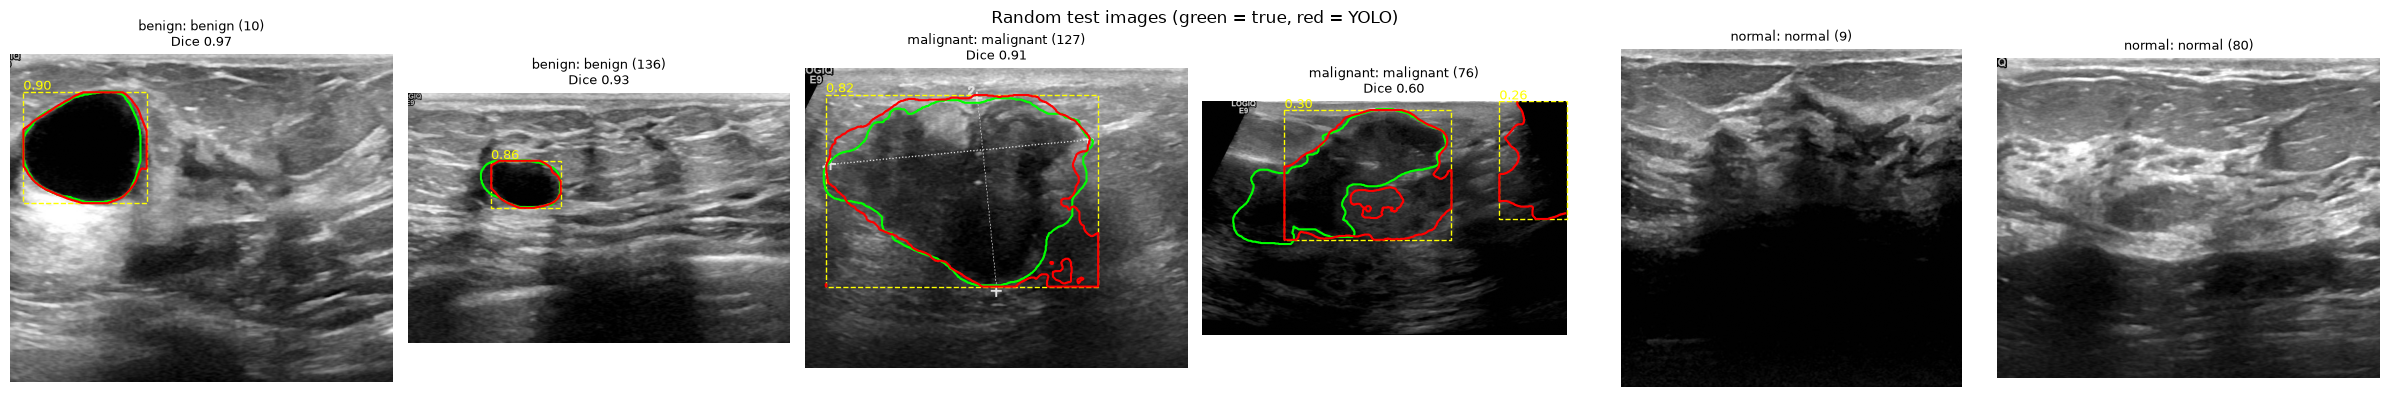

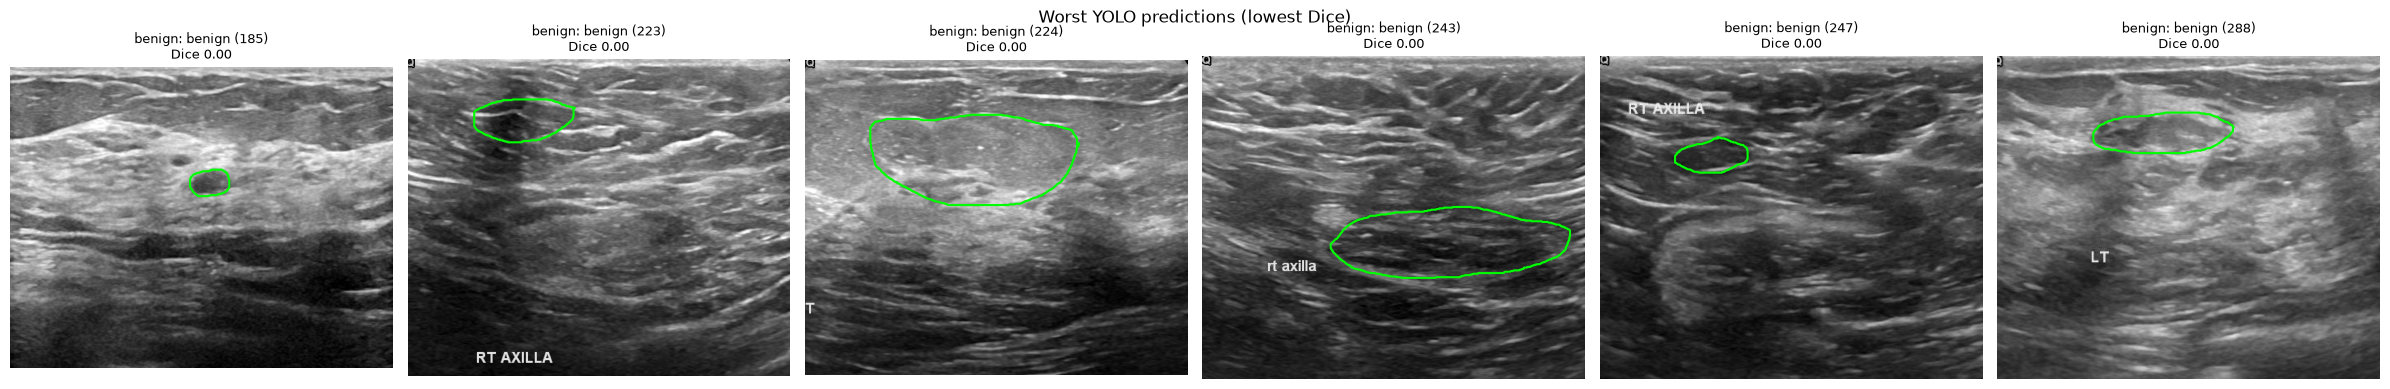

In [12]:
def show_predictions(rows, title, file_name):
    """Show test images with true outline, YOLO mask and boxes, and save the figure."""
    fig, axes = plt.subplots(1, len(rows), figsize=(4 * len(rows), 4), squeeze=False)
    for ax, row in zip(axes[0], rows.itertuples()):
        image = Image.open(DATA_DIR / row.image_path).convert('L')
        truth = load_true_mask(test_df.loc[test_df['image_path'] == row.image_path, 'mask_paths'].iloc[0])
        pred = np.array(Image.open(YOLO_DIR / row.pred_mask_path)) > 127

        ax.imshow(image, cmap='gray')
        if truth.any():
            ax.contour(truth, levels=[0.5], colors='lime', linewidths=1.5)
        if pred.any():
            ax.contour(pred, levels=[0.5], colors='red', linewidths=1.5)
        for detection in all_detections[row.image_path]:
            left, top, right, bottom = detection['box']
            ax.add_patch(patches.Rectangle((left, top), right - left, bottom - top,
                                           fill=False, edgecolor='yellow', linestyle='--', linewidth=1))
            ax.text(left, top - 4, f"{detection['confidence']:.2f}", color='yellow', fontsize=9)

        name = f'{row.label}: {Path(row.image_path).stem}'
        ax.set_title(f'{name}\nDice {row.dice:.2f}' if row.label != 'normal' else name, fontsize=9)
        ax.axis('off')
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(YOLO_DIR / file_name, dpi=120, bbox_inches='tight')
    plt.show()


examples = results.groupby('label', group_keys=False).sample(2, random_state=RANDOM_STATE)   # 2 per class
show_predictions(examples, 'Random test images (green = true, red = YOLO)', 'prediction_examples.png')

worst = results[tumour].nsmallest(6, 'dice')                                             # hardest cases
show_predictions(worst, 'Worst YOLO predictions (lowest Dice)', 'worst_predictions.png')

## 7. Save the config

In [13]:
config = {
    'model_name': 'YOLO11s-seg',
    'architecture': 'yolo',
    'pretrained': PRETRAINED,
    'classes': ['lesion'],
    'image_size': IMAGE_SIZE,
    'conf_threshold': CONF_THRESHOLD,
    'min_lesion_pixels': MIN_LESION_PIXELS,
    'classifies_benign_malignant': False,
    'epochs_trained': int(len(history)),
    'best_epoch': int(history.loc[history['metrics/mAP50-95(M)'].idxmax(), 'epoch']),
    'batch_size': BATCH_SIZE,
    'images': manifest['split'].value_counts().to_dict(),
    'trained_on': datetime.now().strftime('%Y-%m-%d %H:%M'),
}

(YOLO_DIR / 'config.json').write_text(json.dumps(config, indent=2))
print(json.dumps(config, indent=2))

{
  "model_name": "YOLO11s-seg",
  "architecture": "yolo",
  "pretrained": "yolo11s-seg.pt",
  "classes": [
    "lesion"
  ],
  "image_size": 640,
  "conf_threshold": 0.25,
  "min_lesion_pixels": 50,
  "classifies_benign_malignant": false,
  "epochs_trained": 80,
  "best_epoch": 60,
  "batch_size": 8,
  "images": {
    "train": 485,
    "test": 104,
    "val": 104
  },
  "trained_on": "2026-11-11 00:54"
}


## 8. Check: reload and predict, the way the app will

This loads the model from the saved files alone and predicts one test image. Its mask should match the one saved in `masks/` (Dice close to 1).

In [14]:
def load_yolo(folder):
    """Load the trained YOLO model and its config."""
    config = json.loads((folder / 'config.json').read_text())
    return YOLO(folder / 'model.pt'), config


net, saved_config = load_yolo(YOLO_DIR)
sample = results[tumour].iloc[0]
mask, detections = predict_mask(net, Image.open(DATA_DIR / sample['image_path']),
                                conf=saved_config['conf_threshold'], image_size=saved_config['image_size'], device='cpu')
saved_mask = np.array(Image.open(YOLO_DIR / sample['pred_mask_path'])) > 127

print('Image:       ', sample['image_path'])
print('Detections:  ', detections)
print(f'Lesion pixels: {mask.sum()}')
print(f'Match with saved mask (Dice): {dice_score(mask, saved_mask):.3f}  (should be close to 1)')

Image:        benign/benign (10).png
Detections:   [{'confidence': 0.901, 'box': [23.2, 67.0, 243.7, 265.2]}]
Lesion pixels: 35050
Match with saved mask (Dice): 1.000  (should be close to 1)


## 9. Compare all the models

This table collects the test results of every model that has been run.

To fill in the **measurement** rows for YOLO (count accuracy, lesion F1, size and centre errors), run `04_measure.ipynb` with `MODEL = 'yolo'`, then run this cell again.

In [15]:
compare = {
    # Outline quality
    'dice_tumour_images': 'Dice (tumour images)',
    'iou_tumour_images': 'IoU (tumour images)',
    'dice_benign': 'Dice (benign)',
    'dice_malignant': 'Dice (malignant)',
    # Mistakes
    'normal_images_with_false_lesion': 'Normal images with a false lesion',
    'tumour_images_with_no_lesion_found': 'Tumour images with no lesion found',
    # Measurements (from 04_measure)
    'count_accuracy': 'Lesion count accuracy',
    'lesion_f1': 'Lesion F1',
    'median_area_error_pct': 'Median area error (%)',
    'median_centre_distance_px': 'Median centre distance (px)',
    'shape_agreement': 'Shape agreement',
    # Classification (only models that classify)
    'accuracy': 'Accuracy (normal / benign / malignant)',
    'malignant_recall': 'Malignant recall',
}

table = {}
for name in ['classifier', 'unet', 'unet_multitask', 'yolo']:
    folder = Path('outputs') / name
    scores = {}
    for file_name in ['metrics.json', 'measurement_metrics.json']:
        if (folder / file_name).exists():
            scores.update(json.loads((folder / file_name).read_text()))
    if scores:
        table[name] = scores

comparison = pd.DataFrame(table).reindex(list(compare)).rename(index=compare).astype(float).round(3)
comparison.to_csv('outputs/model_comparison.csv')
comparison

,classifier,unet_multitask,yolo
Dice (tumour images),NaN,0.768,0.751
IoU (tumour images),NaN,0.687,0.679
Dice (benign),NaN,0.779,0.777
Dice (malignant),NaN,0.745,0.701
Normal images with a false lesion,NaN,0.176,0.412
Tumour images with no lesion found,NaN,0.034,0.103
Lesion count accuracy,NaN,0.827,NaN
Lesion F1,NaN,0.775,NaN
Median area error (%),NaN,8.600,NaN
Median centre distance (px),NaN,4.850,NaN
